You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')


Loading LISA Instrument output with PyTDI...
  file    = /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/lisa_instrument_output.h5
  skipped = 2000

Loaded PyTDI Data object
  fs = 10.000000000009095 Hz
Using delay derivatives.

Measurement keys:
  ref_12
  ref_13
  ref_21
  ref_23
  ref_31
  ref_32
  ref_sb_12
  ref_sb_13
  ref_sb_21
  ref_sb_23
  ref_sb_31
  ref_sb_32
  sci_12
  sci_13
  sci_21
  sci_23
  sci_31
  sci_32
  sci_sb_12
  sci_sb_13
  sci_sb_21
  sci_sb_23
  sci_sb_31
  sci_sb_32
  tmi_12
  tmi_13
  tmi_21
  tmi_23
  tmi_31
  tmi_32

Building Michelson X2, Y2, Z2...
Evaluating TDI channels...

TDI diagnostics after crop:
  X2: min=-5.526e+01, max=1.189e+02, std=9.812e-01
  Y2: min=-2.107e+02, max=2.274e+02, std=5.762e+00
  Z2: min=-2.389e+02, max=2.373e+02, std=5.837e+00
  A2: min=-1.831e+02, max=1.694e+02, std=4.288e+00
  E2: min=-2.567e+02, max=2.513e+02, std=6.920e+00
  T2: min=-7.928e+01, max=7.671e+01, std=1.401e+00

Saved TDI CSV: /Users/shubhanshutiwa

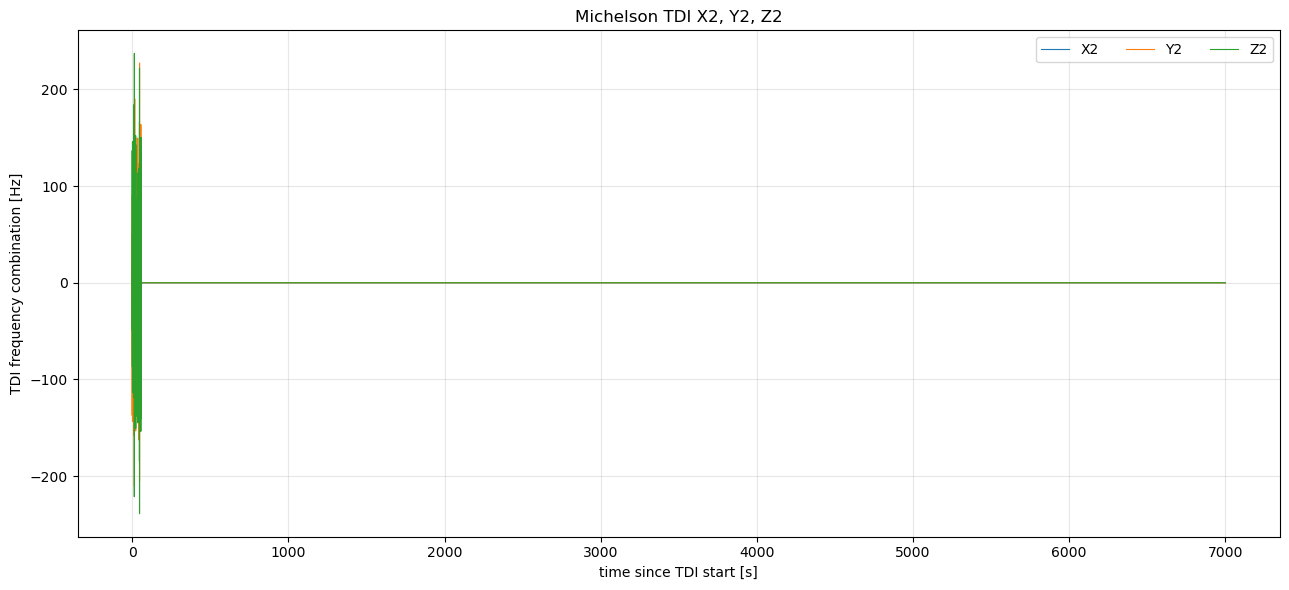

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_michelson_XYZ.png


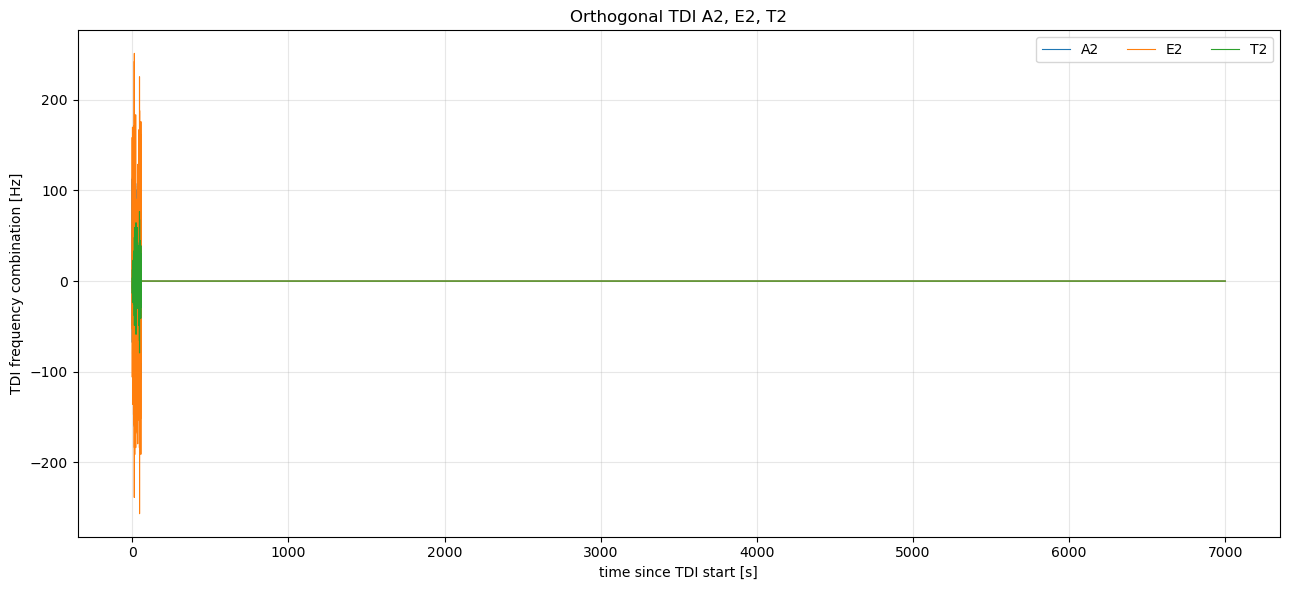

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_michelson_AET.png

Done.
  CSV      = /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/tdi_michelson_XYZ_AET.csv
  XYZ plot = /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_michelson_XYZ.png
  AET plot = /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_michelson_AET.png


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytdi import Data
import pytdi.michelson


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"

TDI_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
PLOT_XYZ = PLOT_DIR / "tdi_michelson_XYZ.png"
PLOT_AET = PLOT_DIR / "tdi_michelson_AET.png"


# ============================================================
# Settings
# ============================================================

SKIPPED = 2000

# Because your lisainstrument output is frequency fluctuations.
UNIT = "frequency"

# Your installed PyTDI supports order keyword.
INTERP_ORDER = 31

# Use second-generation Michelson for moving LISA arms.
GENERATION = 2

# Since merger is now in the middle, we can safely crop edges.
# If your simulation is short, reduce this to e.g. 1000 or 0.
EDGE_CROP = 0


# ============================================================
# Helpers
# ============================================================

def get_delay_derivatives_if_available(data):
    if hasattr(data, "delay_derivatives"):
        return data.delay_derivatives
    if hasattr(data, "delay_derivs"):
        return data.delay_derivs
    if hasattr(data, "derivatives"):
        return data.derivatives
    return None


def crop_edges(arr, edge_crop):
    if edge_crop <= 0:
        return arr

    if len(arr) <= 2 * edge_crop:
        print(
            f"Warning: array length {len(arr)} too short for EDGE_CROP={edge_crop}. "
            "No crop applied."
        )
        return arr

    return arr[edge_crop:-edge_crop]


def save_and_plot(t, channels, title, ylabel, out_png):
    plt.figure(figsize=(13, 6))

    for name, arr in channels.items():
        plt.plot(t, arr, linewidth=0.8, label=name)

    plt.xlabel("time since TDI start [s]")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(ncol=3)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_png, dpi=150)
    plt.show()

    print(f"Saved plot: {out_png}")


# ============================================================
# Main
# ============================================================

def main():
    if not INSTRUMENT_FILE.exists():
        raise FileNotFoundError(f"Missing instrument file: {INSTRUMENT_FILE}")

    print("Loading LISA Instrument output with PyTDI...")
    print(f"  file    = {INSTRUMENT_FILE}")
    print(f"  skipped = {SKIPPED}")

    data = Data.from_instrument(
        str(INSTRUMENT_FILE),
        signals="fluctuations",
        skipped=SKIPPED,
    )

    print("\nLoaded PyTDI Data object")
    print(f"  fs = {data.fs} Hz")

    delay_derivatives = get_delay_derivatives_if_available(data)

    if delay_derivatives is None:
        print("Warning: no delay derivatives found. Building without delay_derivatives.")
    else:
        print("Using delay derivatives.")

    print("\nMeasurement keys:")
    for key in sorted(data.measurements.keys()):
        print(f"  {key}")

    # --------------------------------------------------------
    # Choose Michelson generation
    # --------------------------------------------------------

    if GENERATION == 2:
        X_comb = pytdi.michelson.X2
        Y_comb = pytdi.michelson.Y2
        Z_comb = pytdi.michelson.Z2
        label_suffix = "2"
    elif GENERATION == 1:
        X_comb = pytdi.michelson.X1
        Y_comb = pytdi.michelson.Y1
        Z_comb = pytdi.michelson.Z1
        label_suffix = "1"
    else:
        raise ValueError("GENERATION must be 1 or 2.")

    print(f"\nBuilding Michelson X{label_suffix}, Y{label_suffix}, Z{label_suffix}...")

    build_kwargs = {"order": INTERP_ORDER}

    if delay_derivatives is not None:
        build_kwargs["delay_derivatives"] = delay_derivatives

    # Your PyTDI signature is:
    # build(delays, fs, delay_derivatives=None, *, order=5, delta=1e-12, maxiter=10)
    X_built = X_comb.build(data.delays, data.fs, **build_kwargs)
    Y_built = Y_comb.build(data.delays, data.fs, **build_kwargs)
    Z_built = Z_comb.build(data.delays, data.fs, **build_kwargs)

    print("Evaluating TDI channels...")

    X = X_built(data.measurements, unit=UNIT)
    Y = Y_built(data.measurements, unit=UNIT)
    Z = Z_built(data.measurements, unit=UNIT)

    # --------------------------------------------------------
    # A, E, T from X, Y, Z
    # --------------------------------------------------------

    A = (Z - X) / np.sqrt(2.0)
    E = (X - 2.0 * Y + Z) / np.sqrt(6.0)
    T = (X + Y + Z) / np.sqrt(3.0)

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))

    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]

    t = (np.arange(n) + SKIPPED) / data.fs

    # --------------------------------------------------------
    # Crop edge transients
    # --------------------------------------------------------

    X = crop_edges(X, EDGE_CROP)
    Y = crop_edges(Y, EDGE_CROP)
    Z = crop_edges(Z, EDGE_CROP)
    A = crop_edges(A, EDGE_CROP)
    E = crop_edges(E, EDGE_CROP)
    T = crop_edges(T, EDGE_CROP)
    t = crop_edges(t, EDGE_CROP)

    n = min(len(t), len(X), len(Y), len(Z), len(A), len(E), len(T))

    t = t[:n]
    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]

    # Shift time axis to start at zero after crop
    t = t - t[0]

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------

    print("\nTDI diagnostics after crop:")
    for name, arr in {
        f"X{label_suffix}": X,
        f"Y{label_suffix}": Y,
        f"Z{label_suffix}": Z,
        f"A{label_suffix}": A,
        f"E{label_suffix}": E,
        f"T{label_suffix}": T,
    }.items():
        print(
            f"  {name}: "
            f"min={np.nanmin(arr):.3e}, "
            f"max={np.nanmax(arr):.3e}, "
            f"std={np.nanstd(arr):.3e}"
        )

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    df = pd.DataFrame(
        {
            "t": t,
            f"X{label_suffix}": X,
            f"Y{label_suffix}": Y,
            f"Z{label_suffix}": Z,
            f"A{label_suffix}": A,
            f"E{label_suffix}": E,
            f"T{label_suffix}": T,
        }
    )

    df.to_csv(TDI_CSV, index=False)
    print(f"\nSaved TDI CSV: {TDI_CSV}")

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    save_and_plot(
        t,
        {
            f"X{label_suffix}": X,
            f"Y{label_suffix}": Y,
            f"Z{label_suffix}": Z,
        },
        title=f"Michelson TDI X{label_suffix}, Y{label_suffix}, Z{label_suffix}",
        ylabel="TDI frequency combination [Hz]",
        out_png=PLOT_XYZ,
    )

    save_and_plot(
        t,
        {
            f"A{label_suffix}": A,
            f"E{label_suffix}": E,
            f"T{label_suffix}": T,
        },
        title=f"Orthogonal TDI A{label_suffix}, E{label_suffix}, T{label_suffix}",
        ylabel="TDI frequency combination [Hz]",
        out_png=PLOT_AET,
    )

    print("\nDone.")
    print(f"  CSV      = {TDI_CSV}")
    print(f"  XYZ plot = {PLOT_XYZ}")
    print(f"  AET plot = {PLOT_AET}")


if __name__ == "__main__":
    main()


GW-only:
  column: gw_12
  min/max/std/rms: -3.4242820167126056e-24 3.3609964960397824e-24 4.021931989253373e-25 4.0219915127450848e-25

Noisy link:
  column: noisy_12
  raw min/max/std/rms: -266.395213055713 280.22902170757266 58.517824738104224 58.54817988469629
  frac min/max/std/rms: -9.454691041336292e-13 9.945669783889539e-13 2.0768689758480482e-13 2.0779463170256558e-13

TDI:
['t', 'X2', 'Y2', 'Z2', 'A2', 'E2', 'T2']
  X2: min=-5.526e+01, max=1.189e+02, std=9.812e-01, rms=9.812e-01
  Y2: min=-2.107e+02, max=2.274e+02, std=5.762e+00, rms=5.762e+00
  Z2: min=-2.389e+02, max=2.373e+02, std=5.837e+00, rms=5.837e+00
  A2: min=-1.831e+02, max=1.694e+02, std=4.288e+00, rms=4.288e+00
  E2: min=-2.567e+02, max=2.513e+02, std=6.920e+00, rms=6.920e+00
  T2: min=-7.928e+01, max=7.671e+01, std=1.401e+00, rms=1.401e+00


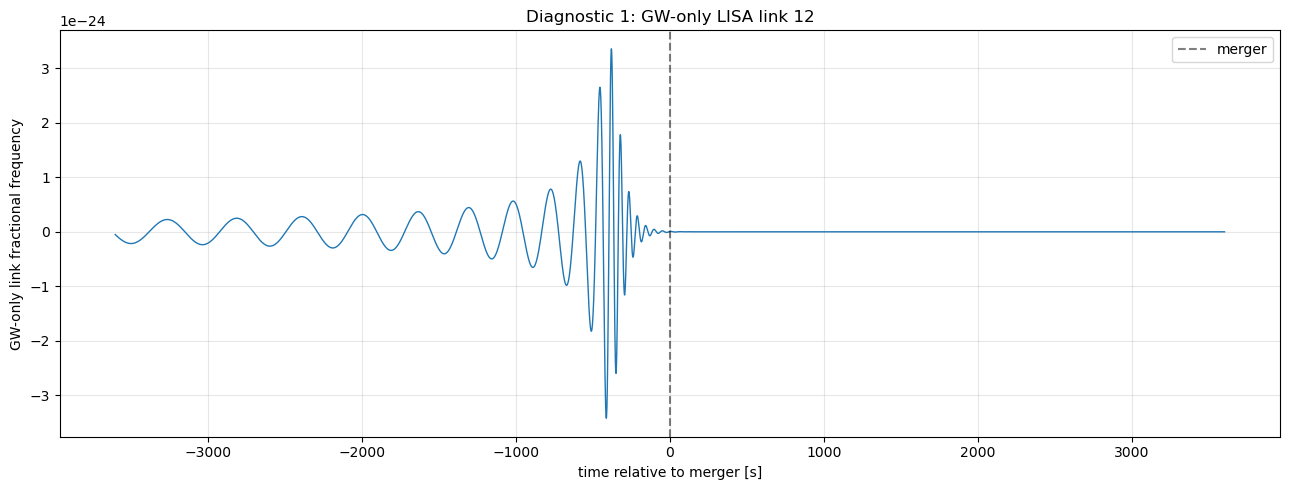

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag1_gw_only_link_12.png


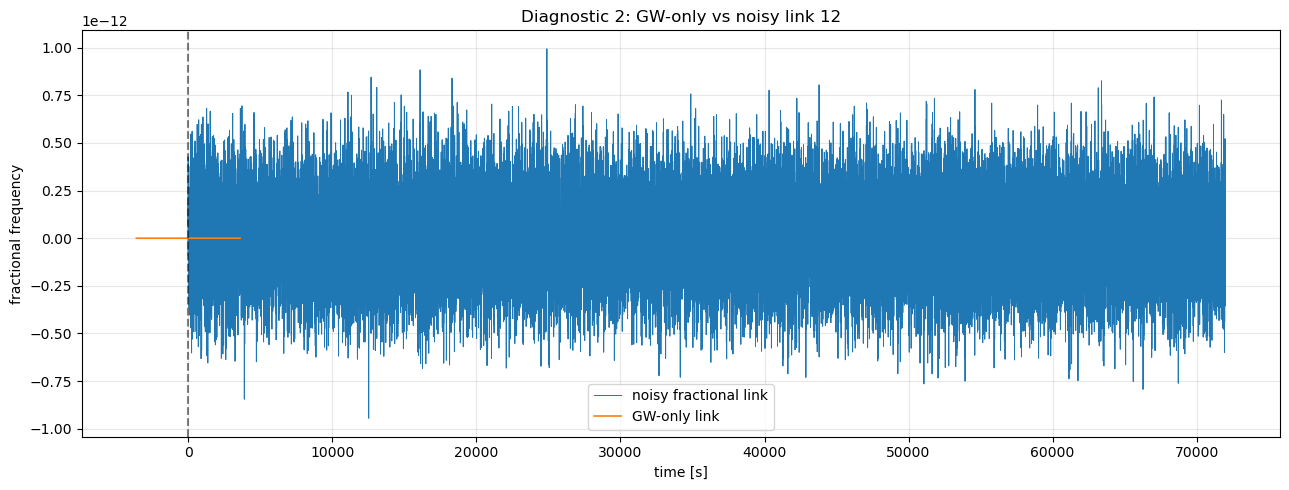

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag2_gw_vs_noisy_link_12.png


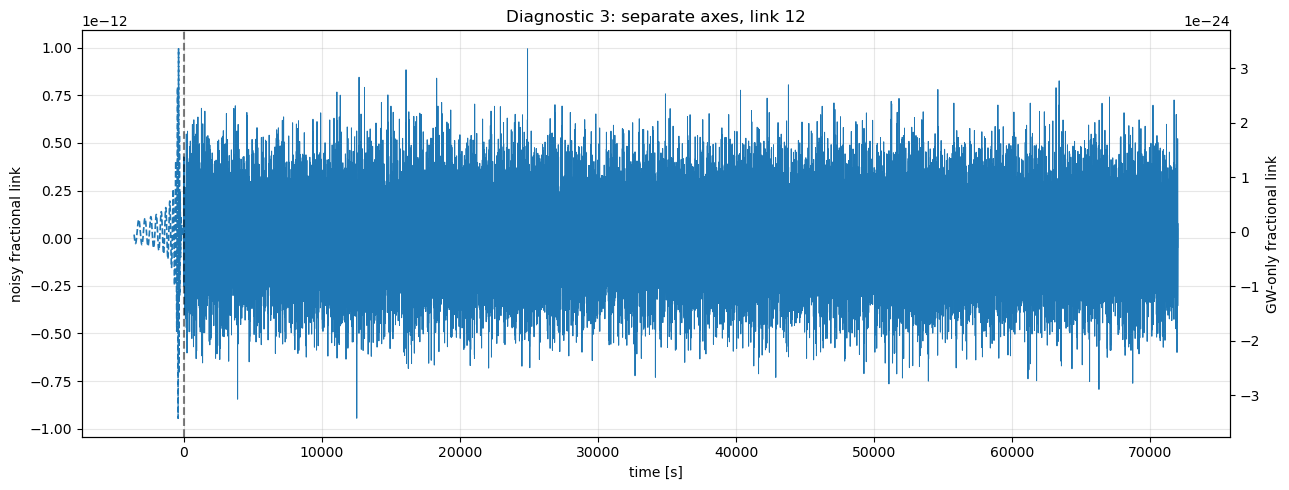

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag3_gw_vs_noisy_twin_link_12.png


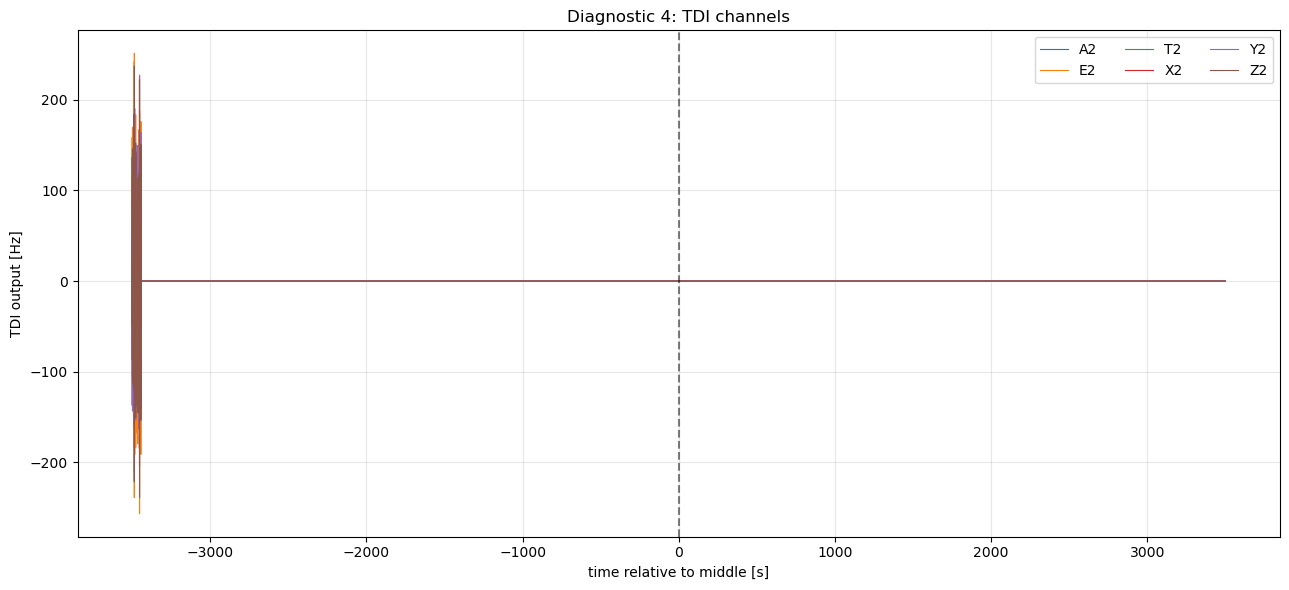

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag4_tdi_timeseries.png


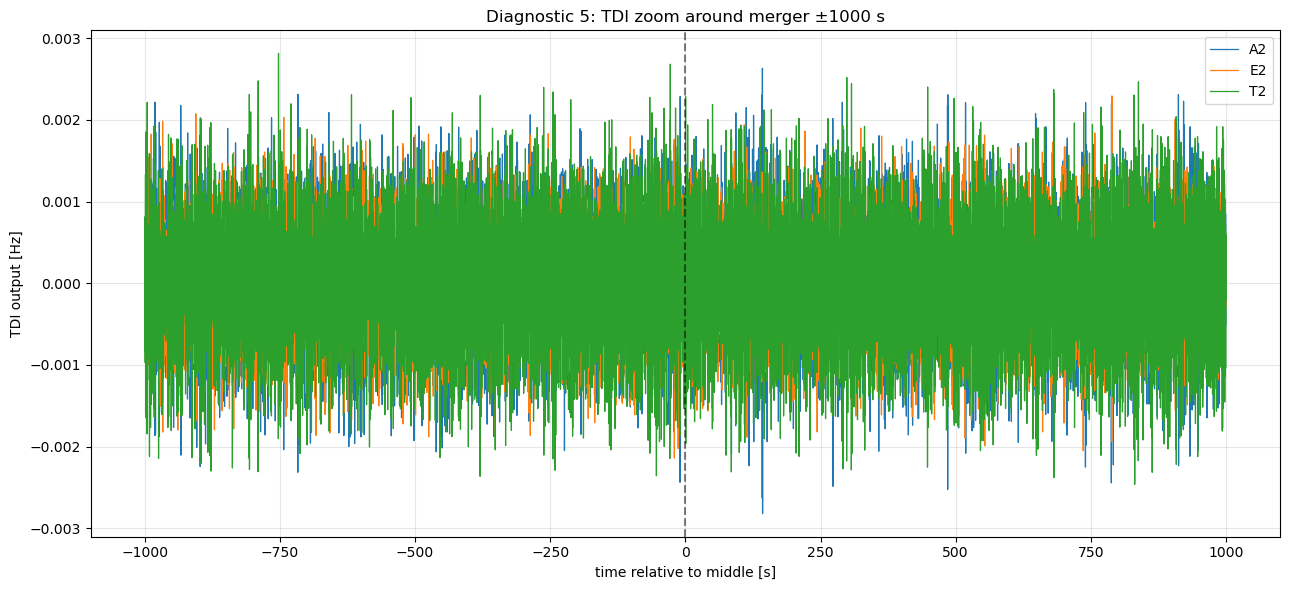

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag5_tdi_zoom_merger.png


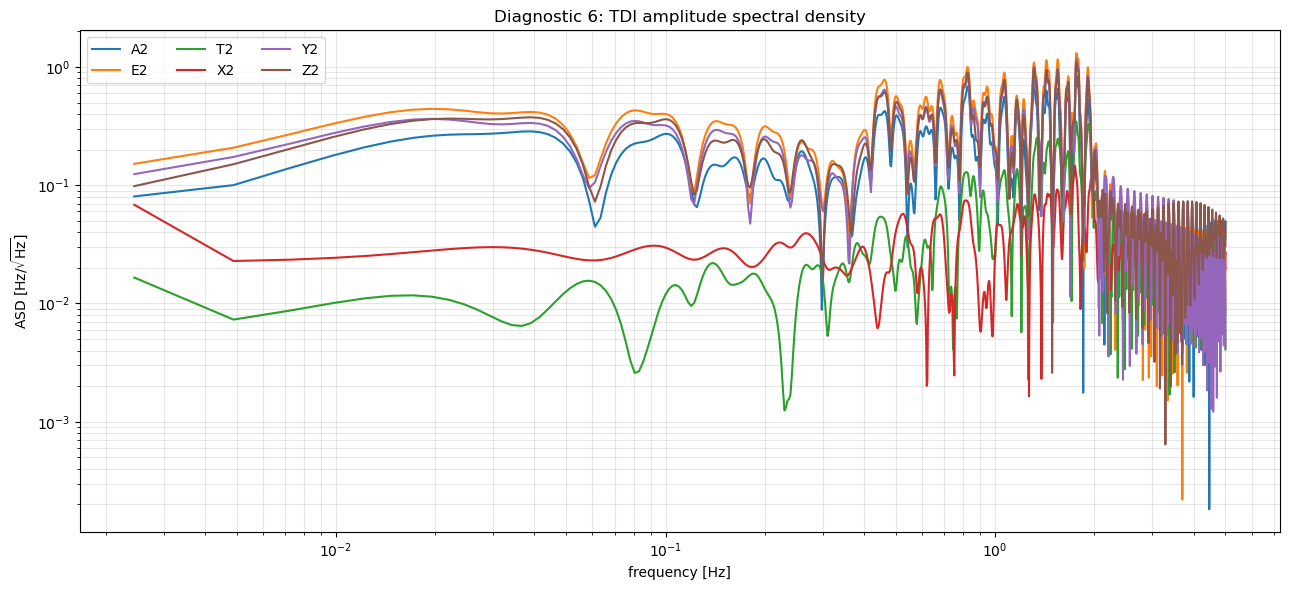

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag6_tdi_asd.png


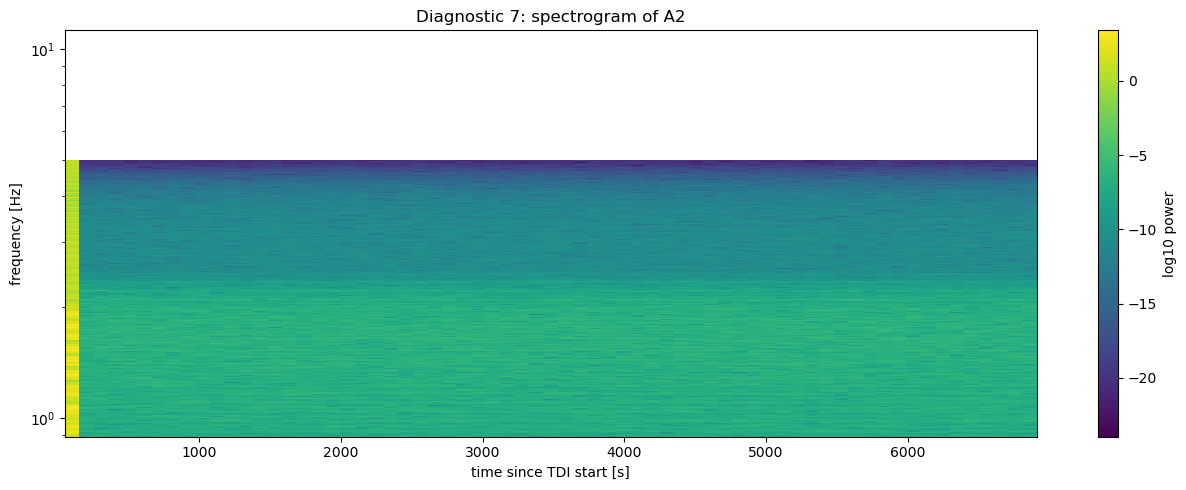

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag7_spectrogram_A2.png


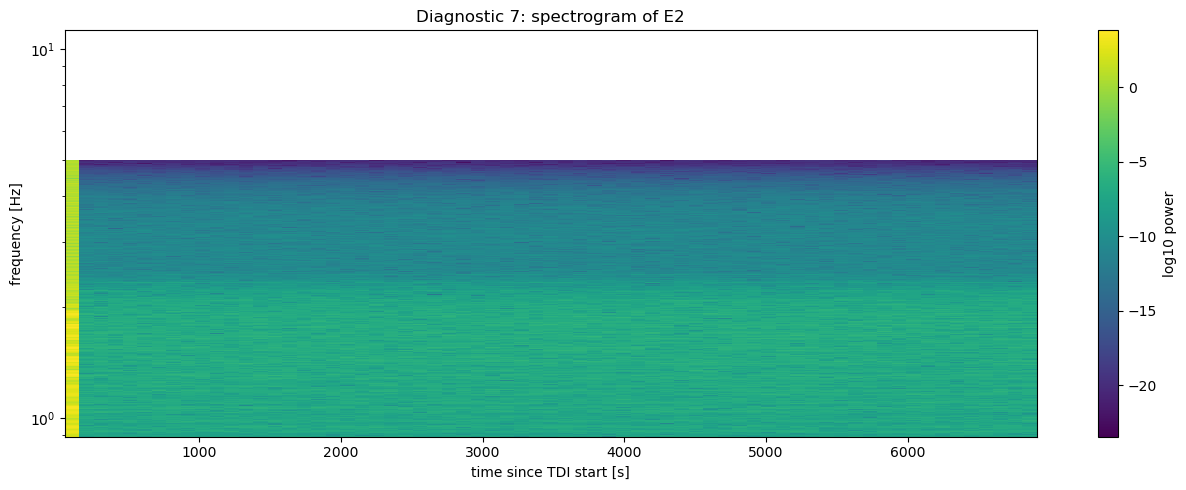

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag7_spectrogram_E2.png


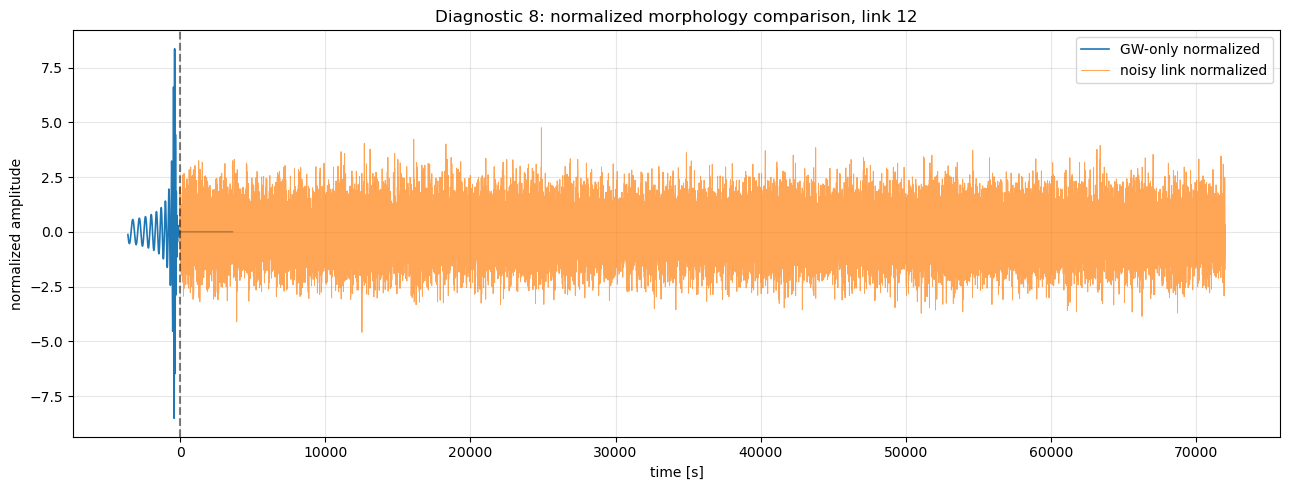

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/diagnostics/diag8_normalized_link_12.png

HDF5 tree for /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/lisa_instrument_output.h5
  debug/
  debug/ref_carrier_fluctuations/
  debug/ref_carrier_fluctuations/12 shape=(72000,)
  debug/ref_carrier_fluctuations/13 shape=(72000,)
  debug/ref_carrier_fluctuations/21 shape=(72000,)
  debug/ref_carrier_fluctuations/23 shape=(72000,)
  debug/ref_carrier_fluctuations/31 shape=(72000,)
  debug/ref_carrier_fluctuations/32 shape=(72000,)
  debug/ref_carrier_offsets/
  debug/ref_carrier_offsets/12 shape=(72000,)
  debug/ref_carrier_offsets/13 shape=(72000,)
  debug/ref_carrier_offsets/21 shape=(72000,)
  debug/ref_carrier_offsets/23 shape=(72000,)
  debug/ref_carrier_offsets/31 shape=(72000,)
  debug/ref_carrier_offsets/32 shape=(72000,)
  debug/ref_usb_fluctuations/
  debug/ref_usb_fluctuations/12 shape=(72000,)
  debug/ref_usb_fluctuations/13 shape=(72000,)
  debug/r

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from scipy.signal import welch, spectrogram


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "diagnostics"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"
NOISY_CSV = OUTPUT_DIR / "six_links_noisy.csv"
TDI_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"


# ============================================================
# Settings
# ============================================================

LINK = "12"

# If noisy CSV is in Hz, divide by optical frequency.
# If already fractional, set False.
CONVERT_NOISY_HZ_TO_FRACTIONAL = True

C = 299_792_458.0
LAMBDA_LASER = 1064e-9
NU0 = C / LAMBDA_LASER

FS_GUESS = None   # leave None to infer from CSV


# ============================================================
# Helpers
# ============================================================

def find_col(df, contains, exclude=("t", "t_lisa", "tau_to_merger", "sample")):
    cols = [c for c in df.columns if contains in c and c not in exclude]
    if not cols:
        raise ValueError(f"No column containing {contains}. Columns = {list(df.columns)}")
    return cols[0]


def time_from_gw(df):
    if "tau_to_merger" in df.columns:
        return df["tau_to_merger"].to_numpy(), "time relative to merger [s]"
    if "t_lisa" in df.columns:
        t = df["t_lisa"].to_numpy()
        return t - t[len(t)//2], "time relative to middle [s]"
    if "t" in df.columns:
        t = df["t"].to_numpy()
        return t - t[len(t)//2], "time relative to middle [s]"
    return np.arange(len(df)), "sample"


def time_from_df(df):
    if "t" in df.columns:
        t = df["t"].to_numpy()
        return t - t[len(t)//2], "time relative to middle [s]"
    if "t_lisa" in df.columns:
        t = df["t_lisa"].to_numpy()
        return t - t[len(t)//2], "time relative to middle [s]"
    if "sample" in df.columns:
        return df["sample"].to_numpy(), "sample"
    return np.arange(len(df)), "sample"


def infer_fs(t):
    dt = np.median(np.diff(t))
    if dt <= 0:
        return None
    return 1.0 / dt


def rms(x):
    return np.sqrt(np.nanmean(x**2))


def plot_and_save(name):
    path = PLOT_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()
    print("Saved:", path)


def print_h5_tree(filename, max_depth=3):
    print(f"\nHDF5 tree for {filename}")
    with h5py.File(filename, "r") as f:
        def visitor(name, obj):
            depth = name.count("/")
            if depth <= max_depth:
                if isinstance(obj, h5py.Dataset):
                    print(f"  {name} shape={obj.shape}")
                else:
                    print(f"  {name}/")
        f.visititems(visitor)


# ============================================================
# Load
# ============================================================

gw = pd.read_csv(GW_ONLY_CSV)
tdi = pd.read_csv(TDI_CSV)

gw_col = find_col(gw, f"gw_{LINK}")
t_gw, xlab_gw = time_from_gw(gw)
y_gw = gw[gw_col].to_numpy()

print("\nGW-only:")
print("  column:", gw_col)
print("  min/max/std/rms:", np.min(y_gw), np.max(y_gw), np.std(y_gw), rms(y_gw))

has_noisy = NOISY_CSV.exists()
if has_noisy:
    noisy = pd.read_csv(NOISY_CSV)
    noisy_col = find_col(noisy, LINK)
    t_noisy, xlab_noisy = time_from_df(noisy)
    y_noisy = noisy[noisy_col].to_numpy()

    if CONVERT_NOISY_HZ_TO_FRACTIONAL:
        y_noisy_frac = y_noisy / NU0
    else:
        y_noisy_frac = y_noisy.copy()

    print("\nNoisy link:")
    print("  column:", noisy_col)
    print("  raw min/max/std/rms:", np.min(y_noisy), np.max(y_noisy), np.std(y_noisy), rms(y_noisy))
    print("  frac min/max/std/rms:", np.min(y_noisy_frac), np.max(y_noisy_frac), np.std(y_noisy_frac), rms(y_noisy_frac))

print("\nTDI:")
print(list(tdi.columns))
t_tdi, xlab_tdi = time_from_df(tdi)

tdi_cols = [c for c in tdi.columns if c != "t"]
for c in tdi_cols:
    x = tdi[c].to_numpy()
    print(f"  {c}: min={np.min(x):.3e}, max={np.max(x):.3e}, std={np.std(x):.3e}, rms={rms(x):.3e}")


# ============================================================
# Plot 1: input h/LISA link GW-only
# ============================================================

plt.figure(figsize=(13, 5))
plt.plot(t_gw, y_gw, lw=1)
plt.axvline(0, color="k", ls="--", alpha=0.5, label="merger")
plt.xlabel(xlab_gw)
plt.ylabel("GW-only link fractional frequency")
plt.title(f"Diagnostic 1: GW-only LISA link {LINK}")
plt.grid(True, alpha=0.3)
plt.legend()
plot_and_save(f"diag1_gw_only_link_{LINK}.png")


# ============================================================
# Plot 2: noisy vs GW same axis
# ============================================================

if has_noisy:
    n = min(len(t_gw), len(t_noisy), len(y_gw), len(y_noisy_frac))
    plt.figure(figsize=(13, 5))
    plt.plot(t_noisy[:n], y_noisy_frac[:n], lw=0.7, label="noisy fractional link")
    plt.plot(t_gw[:n], y_gw[:n], lw=1.2, label="GW-only link")
    plt.axvline(0, color="k", ls="--", alpha=0.5)
    plt.xlabel("time [s]")
    plt.ylabel("fractional frequency")
    plt.title(f"Diagnostic 2: GW-only vs noisy link {LINK}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plot_and_save(f"diag2_gw_vs_noisy_link_{LINK}.png")


# ============================================================
# Plot 3: noisy vs GW with separate y-axes
# ============================================================

if has_noisy:
    n = min(len(t_gw), len(t_noisy), len(y_gw), len(y_noisy_frac))

    fig, ax1 = plt.subplots(figsize=(13, 5))
    ax1.plot(t_noisy[:n], y_noisy_frac[:n], lw=0.7, label="noisy link")
    ax1.set_ylabel("noisy fractional link")
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    ax2.plot(t_gw[:n], y_gw[:n], lw=1.2, ls="--", label="GW-only link")
    ax2.set_ylabel("GW-only fractional link")

    ax1.axvline(0, color="k", ls="--", alpha=0.5)
    ax1.set_xlabel("time [s]")
    plt.title(f"Diagnostic 3: separate axes, link {LINK}")
    plot_and_save(f"diag3_gw_vs_noisy_twin_link_{LINK}.png")


# ============================================================
# Plot 4: TDI A,E,T time series
# ============================================================

plt.figure(figsize=(13, 6))
for c in ["A2", "E2", "T2", "X2", "Y2", "Z2"]:
    if c in tdi.columns:
        plt.plot(t_tdi, tdi[c].to_numpy(), lw=0.8, label=c)
plt.axvline(0, color="k", ls="--", alpha=0.5)
plt.xlabel(xlab_tdi)
plt.ylabel("TDI output [Hz]")
plt.title("Diagnostic 4: TDI channels")
plt.grid(True, alpha=0.3)
plt.legend(ncol=3)
plot_and_save("diag4_tdi_timeseries.png")


# ============================================================
# Plot 5: zoom around merger
# ============================================================

ZOOM = 1000.0  # seconds around merger

plt.figure(figsize=(13, 6))

for c in ["A2", "E2", "T2"]:
    if c in tdi.columns:
        mask = np.abs(t_tdi) < ZOOM
        plt.plot(t_tdi[mask], tdi[c].to_numpy()[mask], lw=0.9, label=c)

plt.axvline(0, color="k", ls="--", alpha=0.5)
plt.xlabel(xlab_tdi)
plt.ylabel("TDI output [Hz]")
plt.title(f"Diagnostic 5: TDI zoom around merger ±{ZOOM:g} s")
plt.grid(True, alpha=0.3)
plt.legend()
plot_and_save("diag5_tdi_zoom_merger.png")


# ============================================================
# Plot 6: PSD of TDI channels
# ============================================================

# infer sampling from TDI t
dt_tdi = np.median(np.diff(tdi["t"].to_numpy())) if "t" in tdi.columns else None
fs_tdi = 1.0 / dt_tdi if dt_tdi and dt_tdi > 0 else FS_GUESS

if fs_tdi is not None:
    plt.figure(figsize=(13, 6))
    for c in ["A2", "E2", "T2", "X2", "Y2", "Z2"]:
        if c in tdi.columns:
            x = tdi[c].to_numpy()
            x = x - np.nanmean(x)
            nperseg = min(4096, len(x))
            f, pxx = welch(x, fs=fs_tdi, nperseg=nperseg)
            plt.loglog(f[1:], np.sqrt(pxx[1:]), label=c)

    plt.xlabel("frequency [Hz]")
    plt.ylabel(r"ASD [Hz/$\sqrt{\mathrm{Hz}}$]")
    plt.title("Diagnostic 6: TDI amplitude spectral density")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend(ncol=3)
    plot_and_save("diag6_tdi_asd.png")
else:
    print("Skipping PSD: could not infer TDI sampling rate.")


# ============================================================
# Plot 7: spectrogram of A/E
# ============================================================

if fs_tdi is not None:
    for c in ["A2", "E2"]:
        if c in tdi.columns:
            x = tdi[c].to_numpy()
            x = x - np.nanmean(x)
            nperseg = min(2048, len(x)//4)
            if nperseg >= 32:
                f, tt, Sxx = spectrogram(x, fs=fs_tdi, nperseg=nperseg, noverlap=nperseg//2)
                plt.figure(figsize=(13, 5))
                plt.pcolormesh(tt, f, np.log10(Sxx + 1e-300), shading="auto")
                plt.yscale("log")
                plt.xlabel("time since TDI start [s]")
                plt.ylabel("frequency [Hz]")
                plt.title(f"Diagnostic 7: spectrogram of {c}")
                plt.colorbar(label="log10 power")
                plot_and_save(f"diag7_spectrogram_{c}.png")


# ============================================================
# Plot 8: normalized overlay, to see morphology regardless of amplitude
# ============================================================

if has_noisy:
    n = min(len(t_gw), len(t_noisy), len(y_gw), len(y_noisy_frac))

    def norm(x):
        s = np.std(x)
        return (x - np.mean(x)) / s if s > 0 else x

    plt.figure(figsize=(13, 5))
    plt.plot(t_gw[:n], norm(y_gw[:n]), lw=1.2, label="GW-only normalized")
    plt.plot(t_noisy[:n], norm(y_noisy_frac[:n]), lw=0.7, alpha=0.7, label="noisy link normalized")
    plt.axvline(0, color="k", ls="--", alpha=0.5)
    plt.xlabel("time [s]")
    plt.ylabel("normalized amplitude")
    plt.title(f"Diagnostic 8: normalized morphology comparison, link {LINK}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plot_and_save(f"diag8_normalized_link_{LINK}.png")


# ============================================================
# HDF5 tree
# ============================================================

if INSTRUMENT_FILE.exists():
    print_h5_tree(INSTRUMENT_FILE, max_depth=3)

print("\nDiagnostics finished.")
print("Plots saved in:", PLOT_DIR)

You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')


Loading instrument file with PyTDI...
Building TDI...
Evaluating TDI...

Timing check:
  tau min          = -3400.000 s
  tau max          = 3599.900 s
  closest merger   = tau[34000] = 0.000000 s
  sample at merger = 36000

TDI diagnostics:
  X2: min=-5.526e+01, max=1.189e+02, std=9.812e-01
  Y2: min=-2.107e+02, max=2.274e+02, std=5.762e+00
  Z2: min=-2.389e+02, max=2.373e+02, std=5.837e+00
  A2: min=-1.831e+02, max=1.694e+02, std=4.288e+00
  E2: min=-2.567e+02, max=2.513e+02, std=6.920e+00
  T2: min=-7.928e+01, max=7.671e+01, std=1.401e+00

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/tdi_michelson_XYZ_AET.csv


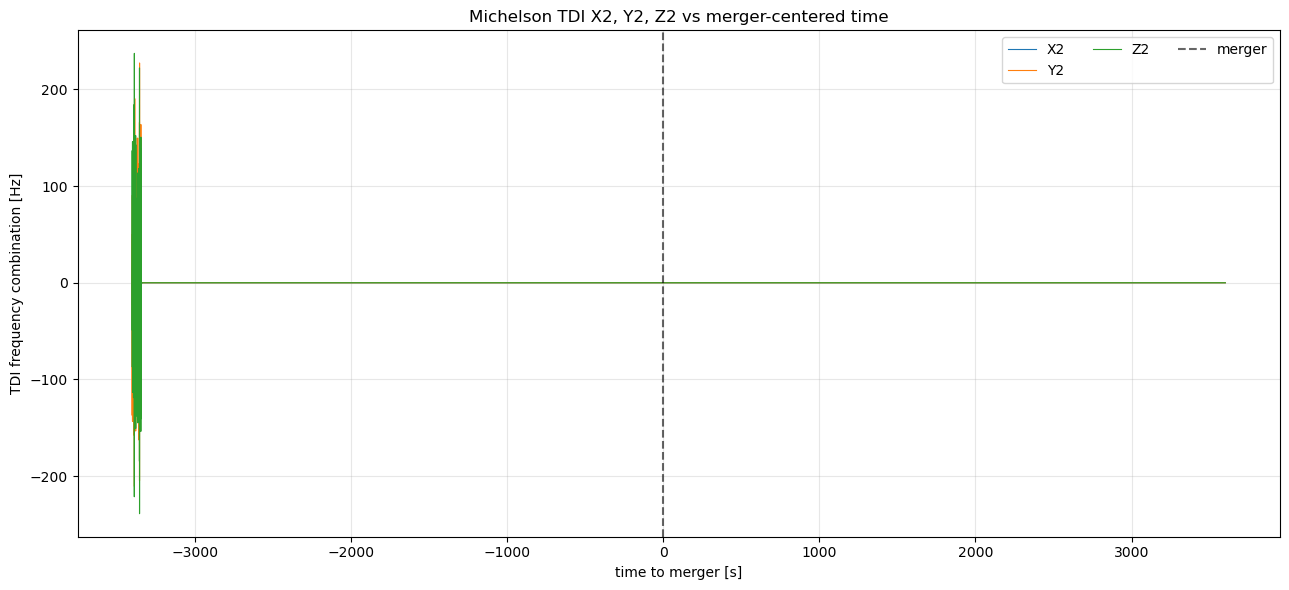

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_XYZ_vs_tau_to_merger.png


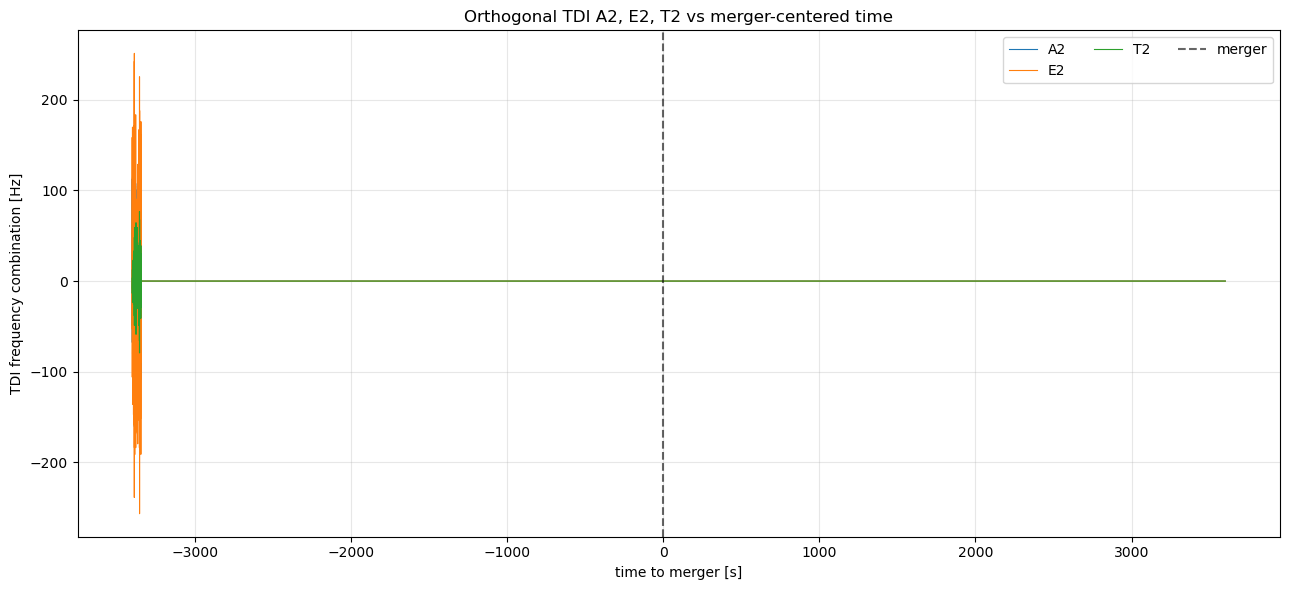

Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/tdi_AET_vs_tau_to_merger.png


In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytdi import Data
import pytdi.michelson


BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"
GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"

TDI_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
PLOT_AET_TAU = PLOT_DIR / "tdi_AET_vs_tau_to_merger.png"
PLOT_XYZ_TAU = PLOT_DIR / "tdi_XYZ_vs_tau_to_merger.png"


# ============================================================
# Settings
# ============================================================

SKIPPED = 2000
EDGE_CROP = 0          # keep 0 for now while debugging
UNIT = "frequency"
INTERP_ORDER = 31
GENERATION = 2


def get_delay_derivatives_if_available(data):
    if hasattr(data, "delay_derivatives"):
        return data.delay_derivatives
    if hasattr(data, "delay_derivs"):
        return data.delay_derivs
    if hasattr(data, "derivatives"):
        return data.derivatives
    return None


def crop(arr, edge):
    if edge <= 0:
        return arr
    if len(arr) <= 2 * edge:
        return arr
    return arr[edge:-edge]


def plot_channels(x, channels, title, ylabel, outfile):
    plt.figure(figsize=(13, 6))
    for name, y in channels.items():
        plt.plot(x, y, lw=0.8, label=name)

    plt.axvline(0.0, color="k", ls="--", alpha=0.6, label="merger")
    plt.xlabel("time to merger [s]")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend(ncol=3)
    plt.tight_layout()
    plt.savefig(outfile, dpi=150)
    plt.show()
    print("Saved:", outfile)


def main():
    gw_meta = pd.read_csv(GW_ONLY_CSV)

    if "tau_to_merger" not in gw_meta.columns:
        raise ValueError("GW_ONLY_CSV must contain tau_to_merger column.")

    if "t" not in gw_meta.columns:
        raise ValueError("GW_ONLY_CSV must contain t column.")

    print("Loading instrument file with PyTDI...")
    data = Data.from_instrument(
        str(INSTRUMENT_FILE),
        signals="fluctuations",
        skipped=SKIPPED,
    )

    delay_derivatives = get_delay_derivatives_if_available(data)

    if GENERATION == 2:
        X_comb = pytdi.michelson.X2
        Y_comb = pytdi.michelson.Y2
        Z_comb = pytdi.michelson.Z2
        suffix = "2"
    else:
        X_comb = pytdi.michelson.X1
        Y_comb = pytdi.michelson.Y1
        Z_comb = pytdi.michelson.Z1
        suffix = "1"

    build_kwargs = {"order": INTERP_ORDER}
    if delay_derivatives is not None:
        build_kwargs["delay_derivatives"] = delay_derivatives

    print("Building TDI...")
    X_built = X_comb.build(data.delays, data.fs, **build_kwargs)
    Y_built = Y_comb.build(data.delays, data.fs, **build_kwargs)
    Z_built = Z_comb.build(data.delays, data.fs, **build_kwargs)

    print("Evaluating TDI...")
    X = X_built(data.measurements, unit=UNIT)
    Y = Y_built(data.measurements, unit=UNIT)
    Z = Z_built(data.measurements, unit=UNIT)

    A = (Z - X) / np.sqrt(2.0)
    E = (X - 2.0 * Y + Z) / np.sqrt(6.0)
    T = (X + Y + Z) / np.sqrt(3.0)

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))

    X, Y, Z = X[:n], Y[:n], Z[:n]
    A, E, T = A[:n], E[:n], T[:n]

    # ========================================================
    # Critical fix:
    # map each PyTDI output sample back to original instrument/GW sample index.
    # PyTDI loaded data after SKIPPED samples, so sample index starts at SKIPPED.
    # ========================================================

    sample_index = np.arange(n) + SKIPPED

    valid = sample_index < len(gw_meta)

    sample_index = sample_index[valid]
    X, Y, Z = X[valid], Y[valid], Z[valid]
    A, E, T = A[valid], E[valid], T[valid]

    t_data = gw_meta["t"].to_numpy()[sample_index]
    tau = gw_meta["tau_to_merger"].to_numpy()[sample_index]

    if "t_lisa" in gw_meta.columns:
        t_lisa = gw_meta["t_lisa"].to_numpy()[sample_index]
    else:
        t_lisa = np.full_like(t_data, np.nan)

    # Optional edge crop, now cropping metadata and TDI consistently
    sample_index = crop(sample_index, EDGE_CROP)
    t_data = crop(t_data, EDGE_CROP)
    tau = crop(tau, EDGE_CROP)
    t_lisa = crop(t_lisa, EDGE_CROP)

    X = crop(X, EDGE_CROP)
    Y = crop(Y, EDGE_CROP)
    Z = crop(Z, EDGE_CROP)
    A = crop(A, EDGE_CROP)
    E = crop(E, EDGE_CROP)
    T = crop(T, EDGE_CROP)

    n = min(len(tau), len(X), len(Y), len(Z), len(A), len(E), len(T))

    sample_index = sample_index[:n]
    t_data = t_data[:n]
    tau = tau[:n]
    t_lisa = t_lisa[:n]

    X, Y, Z = X[:n], Y[:n], Z[:n]
    A, E, T = A[:n], E[:n], T[:n]

    print("\nTiming check:")
    print(f"  tau min          = {tau.min():.3f} s")
    print(f"  tau max          = {tau.max():.3f} s")
    print(f"  closest merger   = tau[{np.argmin(np.abs(tau))}] = {tau[np.argmin(np.abs(tau))]:.6f} s")
    print(f"  sample at merger = {sample_index[np.argmin(np.abs(tau))]}")

    print("\nTDI diagnostics:")
    for name, arr in {
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    }.items():
        print(f"  {name}: min={np.min(arr):.3e}, max={np.max(arr):.3e}, std={np.std(arr):.3e}")

    df = pd.DataFrame({
        "sample": sample_index,
        "t": t_data,
        "tau_to_merger": tau,
        "t_lisa": t_lisa,
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    })

    df.to_csv(TDI_CSV, index=False)
    print("\nSaved:", TDI_CSV)

    plot_channels(
        tau,
        {f"X{suffix}": X, f"Y{suffix}": Y, f"Z{suffix}": Z},
        f"Michelson TDI X{suffix}, Y{suffix}, Z{suffix} vs merger-centered time",
        "TDI frequency combination [Hz]",
        PLOT_XYZ_TAU,
    )

    plot_channels(
        tau,
        {f"A{suffix}": A, f"E{suffix}": E, f"T{suffix}": T},
        f"Orthogonal TDI A{suffix}, E{suffix}, T{suffix} vs merger-centered time",
        "TDI frequency combination [Hz]",
        PLOT_AET_TAU,
    )


if __name__ == "__main__":
    main()